# Week 1
# Project Title    : Data-Driven Inventory Management And Demand Forecasting
# Approach        : Machine Learning, Clustering and Inventory Optimization
# Technology     : Python, Pandas, NumPy, Scikit-learn
# Report Type   : Strategic Planning and Data Exploration

# By:
#   V. Thanigai Murugan
#   B.Tech CSE



## A. Load and aggregate transaction data

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

DATA_PATH = Path("inventory_sales.csv")

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
    print(f"Loaded dataset: {DATA_PATH.resolve()}")
else:
    # Demonstration-only fallback: replace this with your actual inventory_sales.csv.
    print("WARNING: inventory_sales.csv was not found. Creating SIMULATED data for demonstration.")
    rng = np.random.default_rng(42)
    dates = pd.date_range("2024-01-01", periods=180, freq="D")
    rows = []
    for product_num in range(1, 9):
        base_demand = rng.integers(8, 35)
        base_price = rng.uniform(50, 500)
        for day_idx, date in enumerate(dates):
            weekly_effect = 1.0 + 0.20 * np.sin(2 * np.pi * day_idx / 7)
            trend = 1 + 0.0008 * day_idx
            units = max(0, int(round(base_demand * weekly_effect * trend + rng.normal(0, 3))))
            rows.append({
                "product_id": f"P{product_num:03d}",
                "date": date,
                "units_sold": units,
                "unit_price": round(float(base_price + rng.normal(0, base_price * 0.02)), 2)
            })
    df = pd.DataFrame(rows)

required_cols = {"product_id", "date", "units_sold", "unit_price"}
missing_cols = required_cols - set(df.columns)
if missing_cols:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_cols)}")

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["units_sold"] = pd.to_numeric(df["units_sold"], errors="coerce")
df["unit_price"] = pd.to_numeric(df["unit_price"], errors="coerce")
df = df.dropna(subset=["product_id", "date", "units_sold", "unit_price"]).copy()
df = df[df["units_sold"] >= 0].copy()

if df.empty:
    raise ValueError("No valid records remain after cleaning the dataset.")

# Aggregate multiple transactions for the same product on the same date.
daily = (
    df.groupby(["product_id", "date"], as_index=False)
      .agg(units_sold=("units_sold", "sum"),
           unit_price=("unit_price", "mean"))
      .sort_values(["product_id", "date"])
      .reset_index(drop=True))

print("Rows in source data:", len(df))
print("Rows in daily product demand:", len(daily))
display(daily.head())
print("\nMissing values in aggregated data:\n", daily.isna().sum())

Rows in source data: 1440
Rows in daily product demand: 1440


,product_id,date,units_sold,unit_price
0,P001,2024-01-01,12,252.15
1,P001,2024-01-02,6,241.05
2,P001,2024-01-03,12,245.93
3,P001,2024-01-04,11,243.27
4,P001,2024-01-05,12,251.35



Missing values in aggregated data:
 product_id    0
date          0
units_sold    0
unit_price    0
dtype: int64


## B. Feature engineering without future-data leakage

In [2]:
daily["day_of_week"] = daily["date"].dt.dayofweek
daily["month"] = daily["date"].dt.month
daily["day_of_year"] = daily["date"].dt.dayofyear
grouped = daily.groupby("product_id", group_keys=False)
daily["lag_1"] = grouped["units_sold"].shift(1)
daily["lag_7"] = grouped["units_sold"].shift(7)
daily["rolling_mean_7"] = grouped["units_sold"].transform(lambda s: s.shift(1).rolling(window=7, min_periods=7).mean())
daily["rolling_std_7"] = grouped["units_sold"].transform(lambda s: s.shift(1).rolling(window=7, min_periods=7).std())

feature_cols = ["unit_price", "day_of_week", "month", "day_of_year","lag_1", "lag_7", "rolling_mean_7", "rolling_std_7"]
daily = daily.dropna(subset=feature_cols + ["units_sold"]).reset_index(drop=True)

if daily.empty:
    raise ValueError("Not enough history to create lag/rolling features. Each product needs at least 8 daily observations.")

print("Rows after feature engineering:", len(daily))
display(daily.head())

Rows after feature engineering: 1384


,product_id,date,units_sold,unit_price,day_of_week,month,day_of_year,lag_1,lag_7,rolling_mean_7,rolling_std_7
0,P001,2024-01-08,11,242.75,0,1,8,10.0,12.0,10.142857,2.340126
1,P001,2024-01-09,14,247.25,1,1,9,11.0,6.0,10.000000,2.236068
2,P001,2024-01-10,11,244.12,2,1,10,14.0,12.0,11.142857,1.864454
3,P001,2024-01-11,15,246.73,3,1,11,11.0,11.0,11.000000,1.825742
4,P001,2024-01-12,8,245.75,4,1,12,15.0,12.0,11.571429,2.370453


## C. Chronological train-validation-test split

In [3]:
unique_dates = np.sort(daily["date"].unique())
if len(unique_dates) < 10:
    raise ValueError("The dataset has too few unique dates for a reliable chronological split.")

cutoff_1 = unique_dates[int(len(unique_dates) * 0.70) - 1]
cutoff_2 = unique_dates[int(len(unique_dates) * 0.85) - 1]

train = daily[daily["date"] <= cutoff_1].copy()
valid = daily[(daily["date"] > cutoff_1) & (daily["date"] <= cutoff_2)].copy()
test = daily[daily["date"] > cutoff_2].copy()

features = feature_cols
X_train, y_train = train[features], train["units_sold"]
X_valid, y_valid = valid[features], valid["units_sold"]
X_test, y_test = test[features], test["units_sold"]

if min(len(train), len(valid), len(test)) == 0:
    raise ValueError("Train, validation, or test partition is empty. Use a larger dataset.")

print(f"Train: {len(train)} rows through {train['date'].max().date()}")
print(f"Validation: {len(valid)} rows")
print(f"Test: {len(test)} rows from {test['date'].min().date()} onward")

Train: 968 rows through 2024-05-07
Validation: 208 rows
Test: 208 rows from 2024-06-03 onward


## D. Compare regression models

In [4]:
models = {"Linear Regression": LinearRegression(),"Random Forest": RandomForestRegressor(n_estimators=300, max_depth=15, min_samples_leaf=2,random_state=42, n_jobs=-1),
          "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,random_state=42)}

validation_results = []
fitted_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_valid)
    mae = mean_absolute_error(y_valid, pred)
    rmse = np.sqrt(mean_squared_error(y_valid, pred))
    r2 = r2_score(y_valid, pred) if len(y_valid) > 1 else np.nan
    validation_results.append([name, mae, rmse, r2])
    fitted_models[name] = model

results_df = pd.DataFrame(validation_results, columns=["Model", "MAE", "RMSE", "R2"])
results_df = results_df.sort_values("MAE").reset_index(drop=True)
display(results_df)
best_name = results_df.loc[0, "Model"]
best_model = fitted_models[best_name]
test_pred = best_model.predict(X_test)

test_mae = mean_absolute_error(y_test, test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))
test_r2 = r2_score(y_test, test_pred) if len(y_test) > 1 else np.nan

print("Selected model (validation MAE):", best_name)
print(f"Test MAE: {test_mae:.3f} units")
print(f"Test RMSE: {test_rmse:.3f} units")
print(f"Test R²: {test_r2:.3f}")

,Model,MAE,RMSE,R2
0,Gradient Boosting,2.590237,3.193986,0.891595
1,Random Forest,2.629343,3.243127,0.888234
2,Linear Regression,2.792737,3.466432,0.872312


Selected model (validation MAE): Gradient Boosting
Test MAE: 2.801 units
Test RMSE: 3.492 units
Test R²: 0.889


## E. K-Means inventory segmentation

,avg_daily_demand,demand_std,total_units,avg_price,cluster
product_id,,,,,
P006,36.369942,6.602644,6292,389.666705,0
P003,34.670520,6.288703,5998,357.235376,0
P007,18.225434,4.230432,3153,210.180116,1
P008,17.231214,3.834324,2981,231.355780,1
P001,10.832370,3.341197,1874,247.324046,1
P002,29.838150,5.403201,5162,470.301734,2
P005,25.271676,4.912153,4372,260.435434,3
P004,21.387283,4.233760,3700,348.547283,3


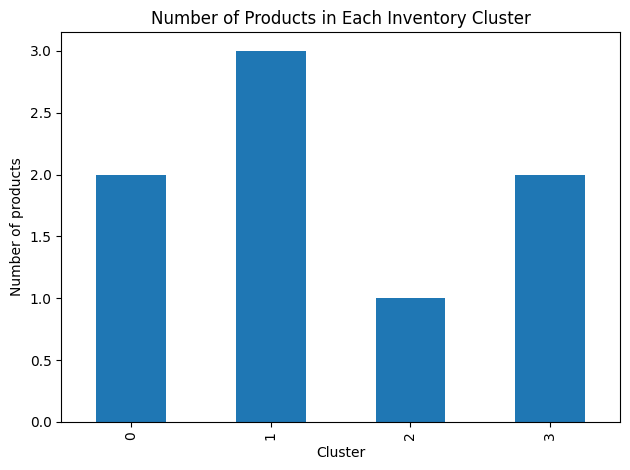

In [5]:
product_features = (daily.groupby("product_id").agg(avg_daily_demand=("units_sold", "mean"),demand_std=("units_sold", "std"),
                    total_units=("units_sold", "sum"),avg_price=("unit_price", "mean")).fillna(0))

if len(product_features) < 4:
    raise ValueError("K-Means with 4 clusters requires at least 4 products.")
scaler = StandardScaler()
Z = scaler.fit_transform(product_features)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=20)
product_features["cluster"] = kmeans.fit_predict(Z)
display(product_features.sort_values(["cluster", "avg_daily_demand"], ascending=[True, False]))
product_features["cluster"].value_counts().sort_index().plot(kind="bar")
plt.title("Number of Products in Each Inventory Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of products")
plt.tight_layout()
plt.show()

## F. Translate forecasts into inventory decisions

In [7]:
service_z = 1.65
lead_time_days = 7

product_features["safety_stock"] = (service_z * product_features["demand_std"] * np.sqrt(lead_time_days))
product_features["reorder_point"] = (product_features["avg_daily_demand"] * lead_time_days + product_features["safety_stock"])

display(product_features[["avg_daily_demand", "demand_std", "safety_stock", "reorder_point", "cluster"]].round(2).head(10))

print("Interpretation: review products with high average demand or high safety stock first.")
print("These are simplified estimates; confirm lead time, service level, and demand assumptions before real use.")

,avg_daily_demand,demand_std,safety_stock,reorder_point,cluster
product_id,,,,,
P001,10.83,3.34,14.59,90.41,1
P002,29.84,5.40,23.59,232.45,2
P003,34.67,6.29,27.45,270.15,0
P004,21.39,4.23,18.48,168.19,3
P005,25.27,4.91,21.44,198.35,3
P006,36.37,6.60,28.82,283.41,0
P007,18.23,4.23,18.47,146.05,1
P008,17.23,3.83,16.74,137.36,1


Interpretation: review products with high average demand or high safety stock first.
These are simplified estimates; confirm lead time, service level, and demand assumptions before real use.
